# 04. Communities and Leakage-Safe Features

This notebook detects Louvain communities from graph structure alone, describes their label composition, and demonstrates how community features are created without test-label leakage.


In [1]:
from pathlib import Path
import os
import sys
import warnings

import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, display


def find_project_root(start: Path) -> Path:
    """Find the repository root whether Jupyter starts there or in notebooks/."""
    for candidate in (start, *start.parents):
        if (candidate / "requirements.txt").exists() and (candidate / "data").exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the project root.")


ROOT = find_project_root(Path.cwd())
os.chdir(ROOT)
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

os.environ.setdefault("PYTHONHASHSEED", "0")
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
print(f"Project root: {ROOT}")


Project root: C:\Users\Jimi\Desktop\github-social-network


## Community detection and description

Louvain uses only the adjacency structure. After the partition is fixed, label composition and community purity are calculated for description and later error analysis. Those full-label summaries are never predictive features.


### Production implementation: Louvain communities and leakage-safe community features

This cell reproduces src/community_analysis.py, which detects Louvain communities, summarizes their size and label composition, and constructs training-label-only community features. It receives the graph, node-to-community mapping, and?where appropriate?the training-node labels; it returns the partition, community summary, or one feature row per requested node. The smoothing rule and missing-training-label fallbacks are kept intact because they prevent unstable estimates while preserving the study?s leakage-safe design.


In [ ]:
from collections import Counter, defaultdict
from typing import Dict, Iterable, Tuple

import networkx as nx
import pandas as pd
import community as community_louvain


def detect_louvain_communities(
    G: nx.Graph,
    random_state: int = 42,
) -> Tuple[Dict[int, int], float]:
    """
    Run Louvain community detection on the full graph structure.

    Returns:
        partition: mapping node_id -> community_id
        modularity: Louvain modularity score
    """
    partition = community_louvain.best_partition(G, random_state=random_state)
    modularity = community_louvain.modularity(partition, G)
    return partition, float(modularity)


def summarize_communities(
    G: nx.Graph,
    labels_dict: Dict[int, int],
    partition: Dict[int, int],
) -> pd.DataFrame:
    """
    Build one summary row per community.

    Output columns:
      community_id, size, web_count, ml_count, web_ratio, ml_ratio,
      dominant_label, purity
    """
    community_nodes: Dict[int, list[int]] = defaultdict(list)
    for node in G.nodes():
        community_id = int(partition.get(node, -1))
        community_nodes[community_id].append(int(node))

    rows = []
    for community_id, nodes in community_nodes.items():
        size = len(nodes)
        web_count = 0
        ml_count = 0
        for node in nodes:
            label = labels_dict.get(node)
            if label == 0:
                web_count += 1
            elif label == 1:
                ml_count += 1

        labeled_total = web_count + ml_count
        if labeled_total == 0:
            web_ratio = 0.0
            ml_ratio = 0.0
            dominant_label = "Web"
            purity = 0.0
        else:
            web_ratio = web_count / labeled_total
            ml_ratio = ml_count / labeled_total
            dominant_label = "Web" if web_count >= ml_count else "ML"
            purity = max(web_ratio, ml_ratio)

        rows.append(
            {
                "community_id": community_id,
                "size": size,
                "web_count": web_count,
                "ml_count": ml_count,
                "web_ratio": web_ratio,
                "ml_ratio": ml_ratio,
                "dominant_label": dominant_label,
                "purity": purity,
            }
        )

    summary_df = pd.DataFrame(rows).sort_values(by="size", ascending=False).reset_index(drop=True)
    return summary_df


def add_community_features(
    G: nx.Graph,
    labels_dict: Dict[int, int],
    train_nodes: Iterable[int],
    nodes: Iterable[int],
    partition: Dict[int, int],
) -> pd.DataFrame:
    """
    Build community-based node features.

    Label-based features are calculated from train labels only.
    """
    train_set = {int(node) for node in train_nodes}
    # Community sizes are structural.  Derive them directly from the
    # label-free Louvain partition rather than from the descriptive summary,
    # which also contains full-dataset label counts and purity values.
    community_size_map = Counter(int(community_id) for community_id in partition.values())

    train_web_count_by_community: Counter[int] = Counter()
    train_ml_count_by_community: Counter[int] = Counter()

    for node in train_set:
        label = labels_dict.get(node)
        if label not in (0, 1):
            continue
        community_id = int(partition.get(node, -1))
        if label == 0:
            train_web_count_by_community[community_id] += 1
        else:
            train_ml_count_by_community[community_id] += 1

    rows = []
    for node in nodes:
        node_int = int(node)
        community_id = int(partition.get(node_int, -1))
        community_size = int(community_size_map.get(community_id, 0))

        train_web = int(train_web_count_by_community.get(community_id, 0))
        train_ml = int(train_ml_count_by_community.get(community_id, 0))
        train_labeled_total = train_web + train_ml

        if train_labeled_total > 0:
            train_ml_ratio = train_ml / train_labeled_total
            train_web_ratio = train_web / train_labeled_total
        else:
            train_ml_ratio = 0.0
            train_web_ratio = 0.0

        rows.append(
            {
                "node_id": node_int,
                "community_id": community_id,
                "community_size": community_size,
                "train_web_in_community": train_web,
                "train_ml_in_community": train_ml,
                "train_ml_ratio_in_community": train_ml_ratio,
                "train_web_ratio_in_community": train_web_ratio,
                "community_train_label_gap": train_ml - train_web,
            }
        )

    return pd.DataFrame(rows)


In [2]:
from community_analysis import (
    add_community_features,
    detect_louvain_communities,
    summarize_communities,
)
from data_loader import load_dataset
from modeling import prepare_train_test_split
from run_core_analysis import _plot_communities

G, _, labels_df, labels_dict = load_dataset(ROOT / "data")
partition, modularity = detect_louvain_communities(G, random_state=SEED)
community_df = summarize_communities(G, labels_dict, partition)

metrics = pd.DataFrame([{
    "number_of_communities": community_df.shape[0],
    "modularity": modularity,
    "largest_community_size": int(community_df["size"].max()),
    "median_community_size": float(community_df["size"].median()),
    "size_weighted_mean_purity": float(
        np.average(community_df["purity"], weights=community_df["size"])
    ),
}])

tables_dir = ROOT / "outputs/tables"
figures_dir = ROOT / "outputs/figures"
tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
community_df.to_csv(tables_dir / "community_summary.csv", index=False)
metrics.to_csv(tables_dir / "community_metrics.csv", index=False)
_plot_communities(community_df, figures_dir)

display(metrics.round(4))
display(community_df.head(12).round(4))


,number_of_communities,modularity,largest_community_size,median_community_size,size_weighted_mean_purity
0,31,0.4534,8732,9.0,0.8298


,community_id,size,web_count,ml_count,web_ratio,ml_ratio,dominant_label,purity
0,7,8732,8165,567,0.9351,0.0649,Web,0.9351
1,2,7664,2181,5483,0.2846,0.7154,ML,0.7154
2,13,6454,5205,1249,0.8065,0.1935,Web,0.8065
3,0,3047,2587,460,0.8490,0.1510,Web,0.8490
4,5,2702,2534,168,0.9378,0.0622,Web,0.9378
5,11,2396,1750,646,0.7304,0.2696,Web,0.7304
6,8,2087,1902,185,0.9114,0.0886,Web,0.9114
7,3,2000,1563,437,0.7815,0.2185,Web,0.7815
8,4,904,649,255,0.7179,0.2821,Web,0.7179
9,10,566,472,94,0.8339,0.1661,Web,0.8339


The partition contains 31 communities with modularity near 0.453. Large communities differ substantially in their Machine Learning share, so community membership is informative but not deterministic.

## Leakage-safe feature creation

For a split, community size and ID come from the label-free partition. Community label counts and ratios are computed from the training nodes only. The test labels are removed from the dictionary passed to feature construction, making accidental access impossible.


In [3]:
train_nodes, test_nodes, y_train, y_test = prepare_train_test_split(
    labels_df, test_size=0.30, random_state=SEED
)
train_labels = {int(node): int(label) for node, label in zip(train_nodes, y_train)}
feature_nodes = np.concatenate([train_nodes, test_nodes])
community_features = add_community_features(
    G, train_labels, train_nodes, feature_nodes, partition
)

display(community_features.head())
assert set(train_labels).isdisjoint(set(test_nodes))
assert "purity" not in community_features.columns
assert "ml_ratio" not in community_features.columns


,node_id,community_id,community_size,train_web_in_community,train_ml_in_community,train_ml_ratio_in_community,train_web_ratio_in_community,community_train_label_gap
0,36331,2,7664,1503,3880,0.720788,0.279212,2377
1,16887,10,566,321,65,0.168394,0.831606,-256
2,4564,7,8732,5726,394,0.064379,0.935621,-5332
3,28542,2,7664,1503,3880,0.720788,0.279212,2377
4,25706,7,8732,5726,394,0.064379,0.935621,-5332


Community purity uses all labels only after prediction to describe where errors occur. It is not passed to any classifier.

## Figures


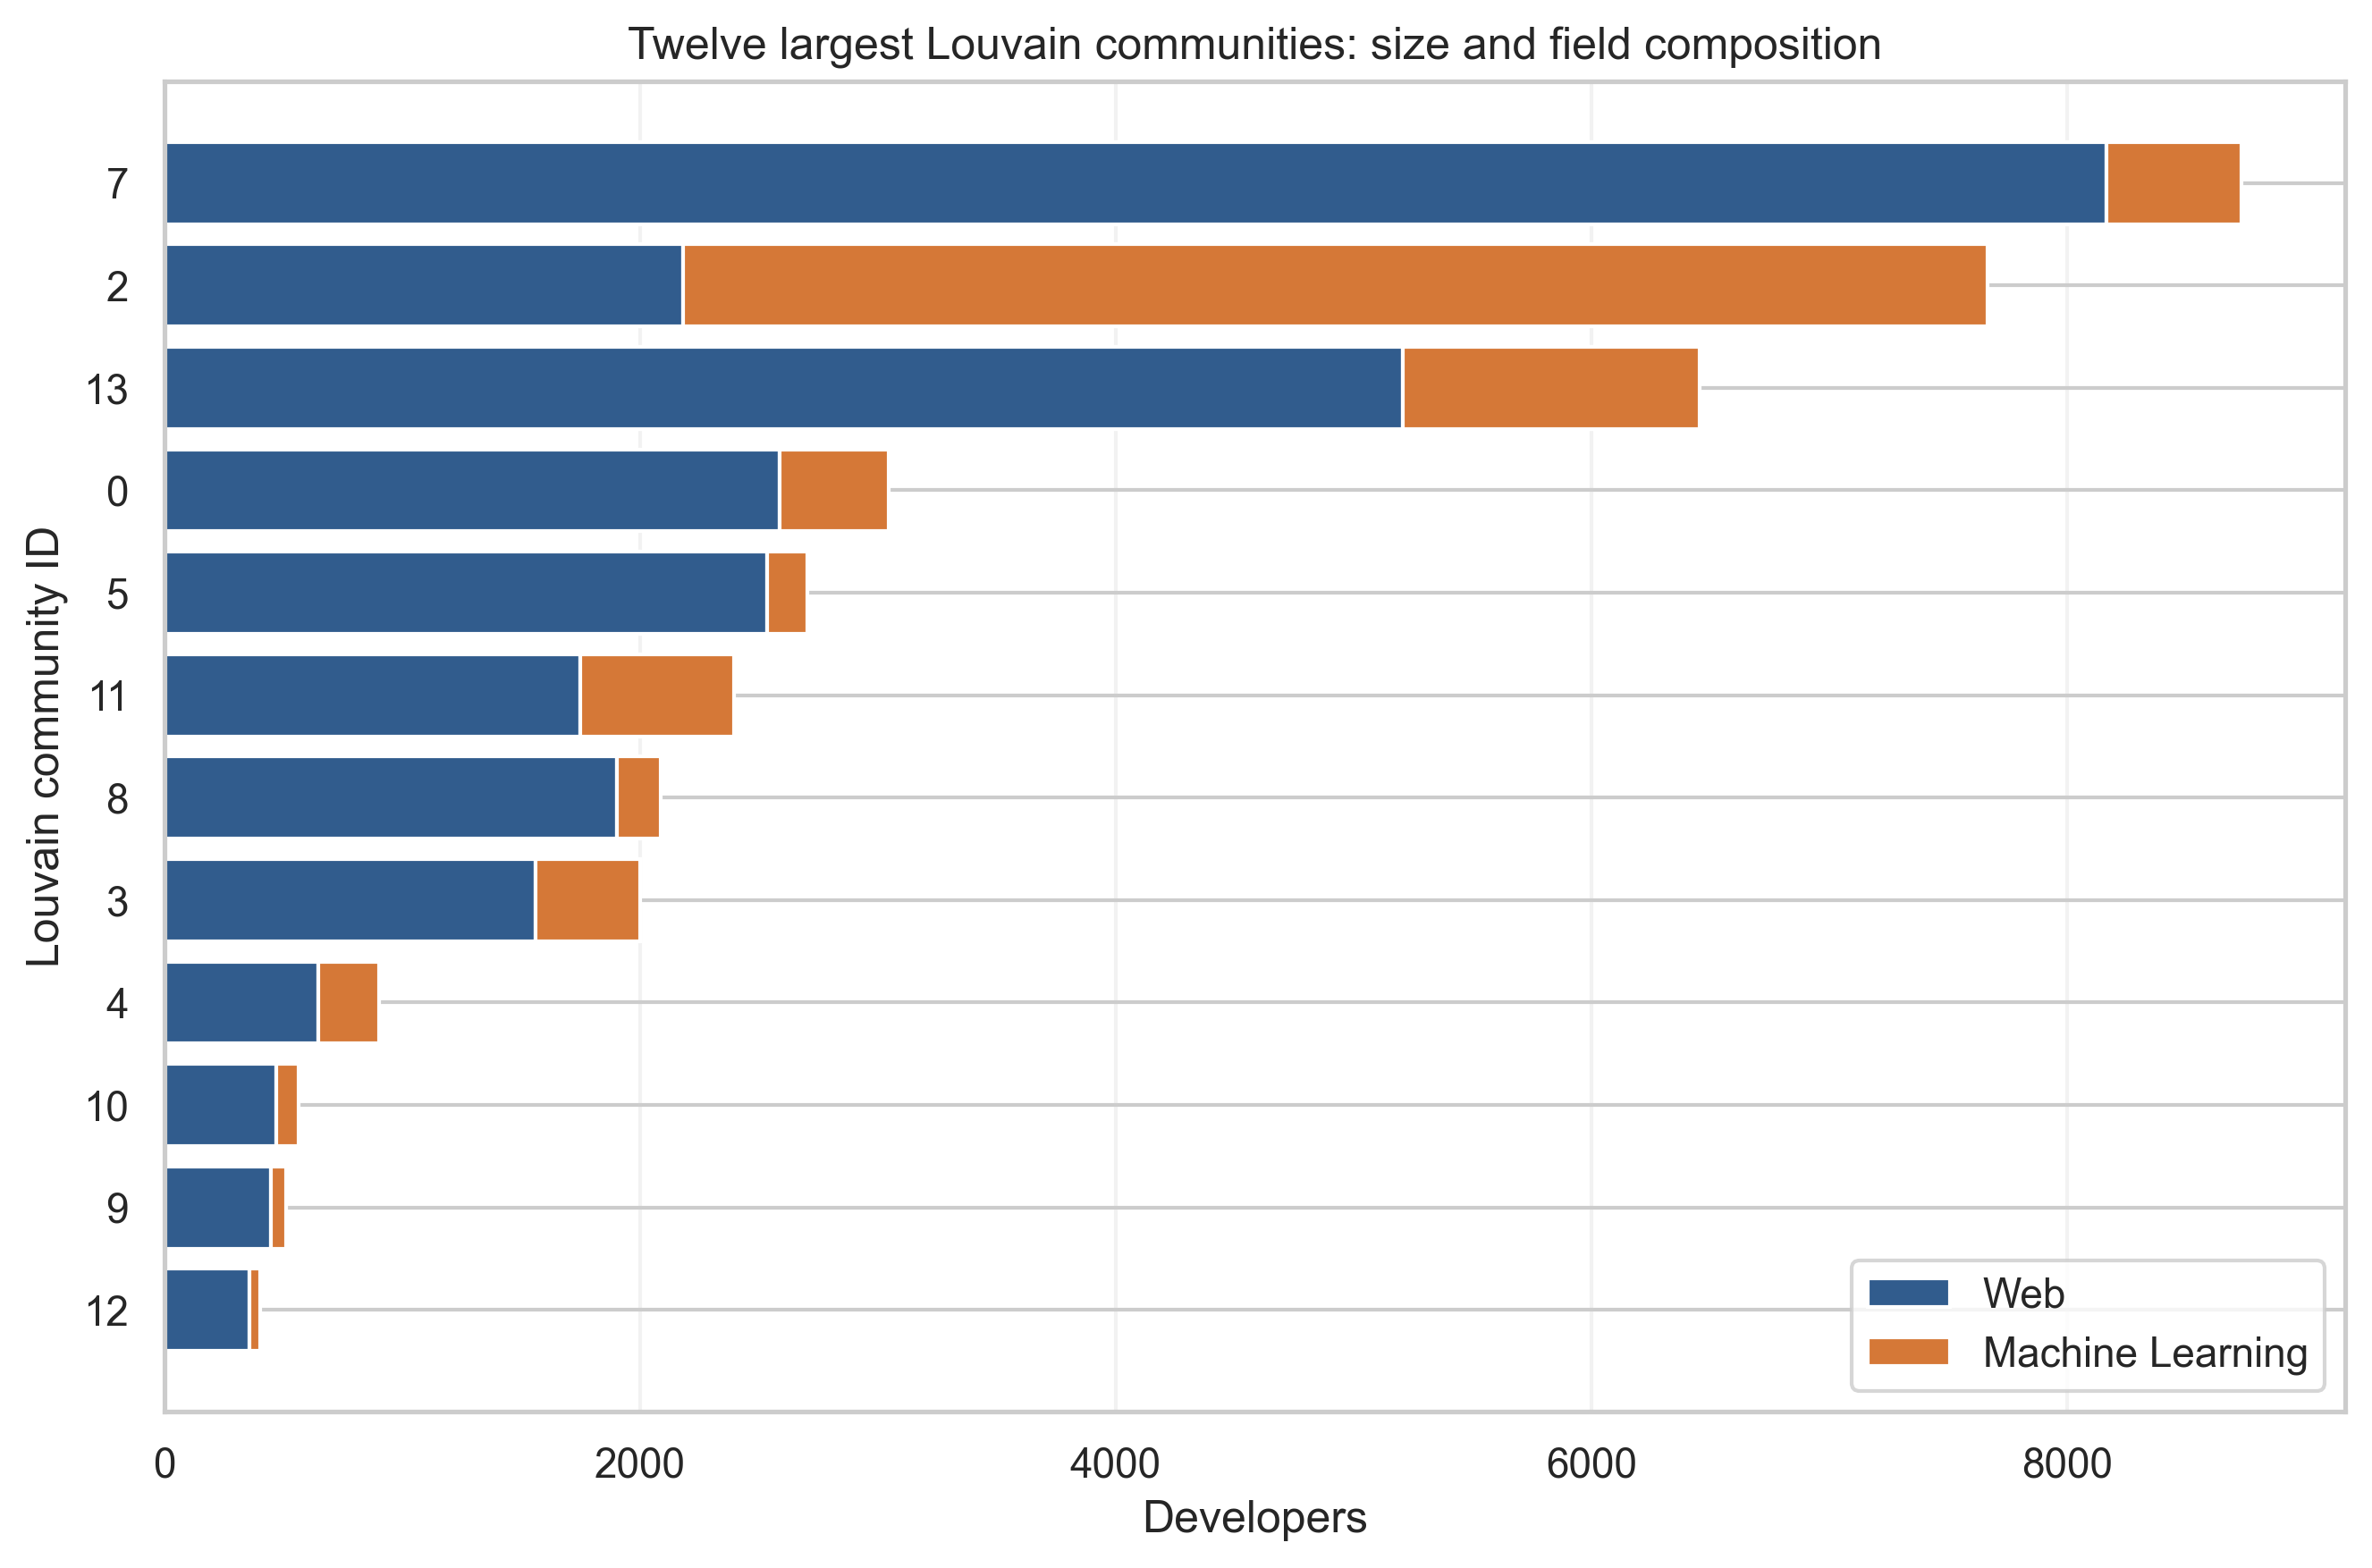

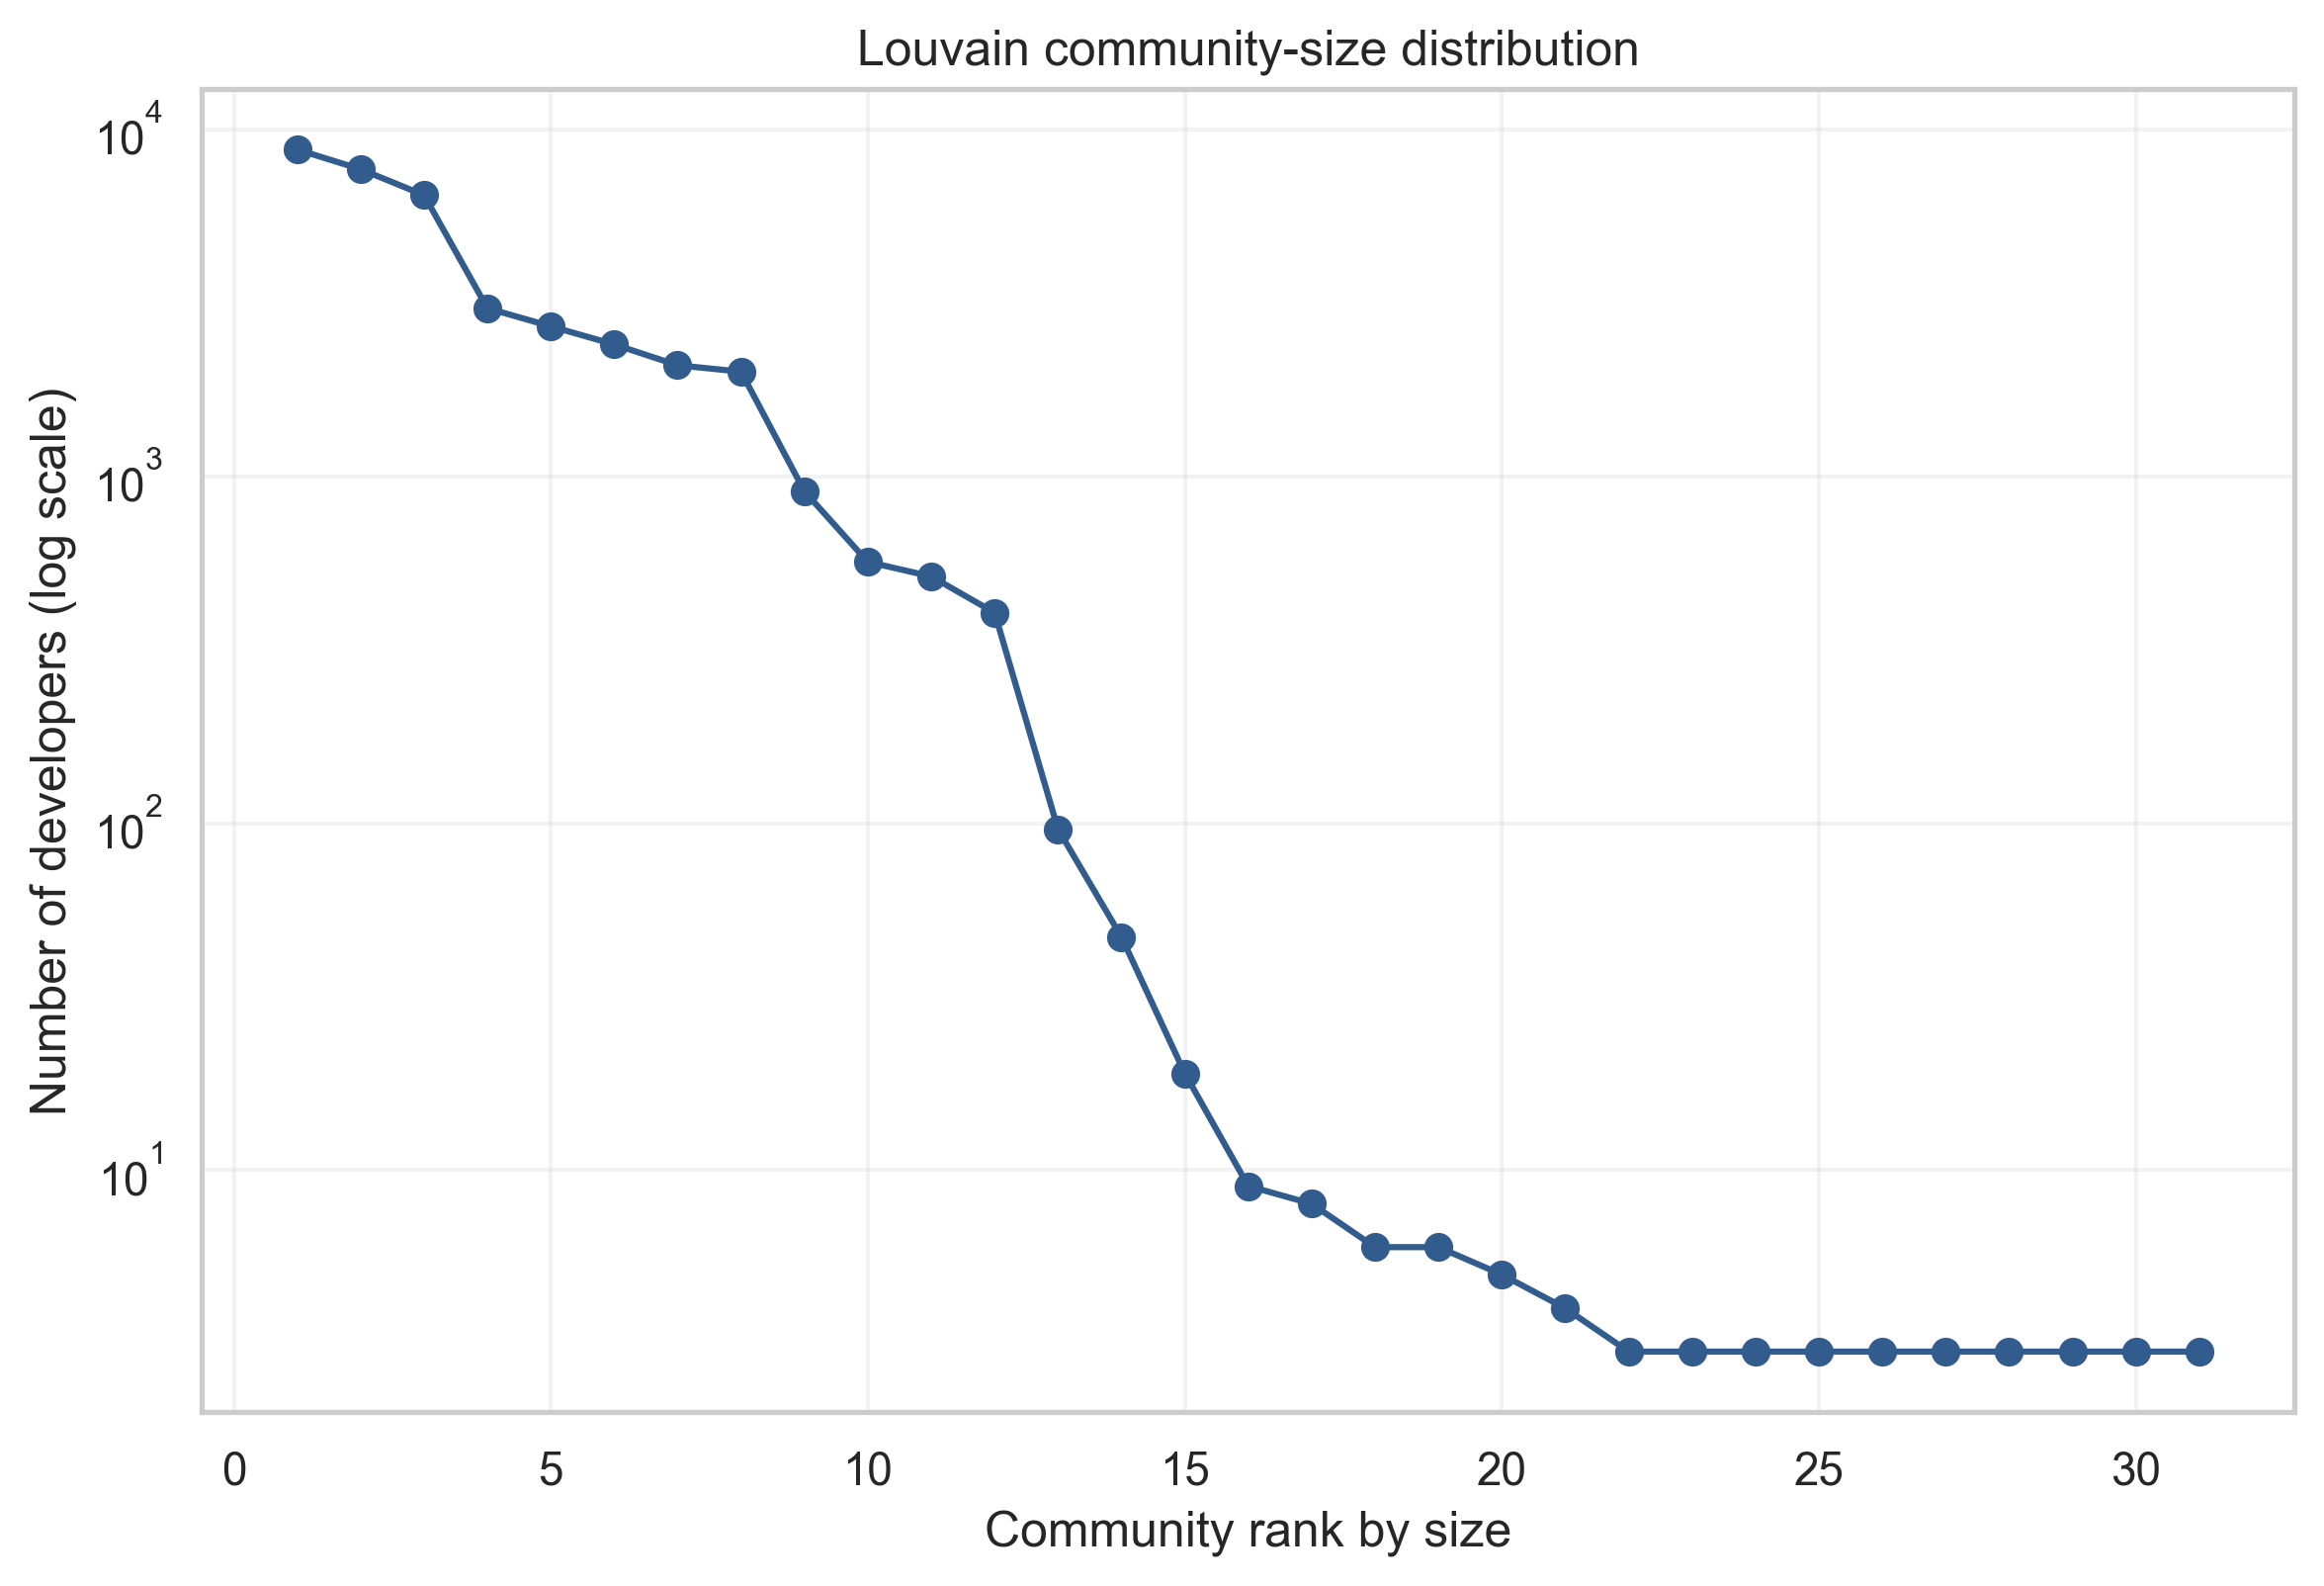

In [4]:
display(Image(filename=str(figures_dir / "community_size_and_composition.png")))
display(Image(filename=str(figures_dir / "community_size_distribution.png")))


## Summary

This Notebook detected Louvain communities from graph structure without using labels. The partition contained 31 communities with modularity 0.4534; the largest community had 8,732 nodes, the median community size was 9, and size-weighted mean purity was 0.8298.

Community composition varied substantially. For example, the largest community was 93.51% Web, while the second-largest community contained 71.54% Machine Learning developers, showing that communities carry field information without determining field perfectly.

The predictive feature demonstration used a stratified 70/30 split and calculated community label counts and ratios from training labels only. Assertions confirmed that test nodes were absent from the training-label dictionary and that full-label purity and full-label ML ratios were not included as classifier features.

The community summary, metrics, leakage-safe feature frame, and community-size and composition figures provide the community-level inputs used by the classification experiments. Full-label purity remains restricted to post-prediction error analysis.
